In [49]:
'''
Submitted by: Criselvi lindsey
Class: DSC640-T301 WK1&2 Milestone 3
Due Date: 04/22/2026
'''

'\nSubmitted by: Criselvi lindsey\nClass: DSC640-T301 WK1&2 Milestone 3\nDue Date: 04/22/2026\n'

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import json
import urllib.request

cols_needed = [
    "State_Name",
    "State_Abbreviation",
    "County_Name",
    "County_FIPS_Code",
    "StudyYear",
    "MCInfant",
    "MCToddler",
    "MCPreschool",
    "MFCCInfant",
    "_75CInfant",
    "MHI",
    "H_Under6_BothWork",
    "H_Under6_SingleM",
    "TotalPop"
]

df = pd.read_excel(
    "nationaldatabaseofchildcareprices.xlsx",
    usecols=cols_needed
)

# Preview data
print(df.head())
print(df.columns.tolist())
# df.columns

  State_Name State_Abbreviation     County_Name  County_FIPS_Code  StudyYear  \
0    Alabama                 AL  Autauga County              1001       2008   
1    Alabama                 AL  Autauga County              1001       2009   
2    Alabama                 AL  Autauga County              1001       2010   
3    Alabama                 AL  Autauga County              1001       2011   
4    Alabama                 AL  Autauga County              1001       2012   

       MHI  TotalPop  H_Under6_BothWork  H_Under6_SingleM  MCInfant  \
0  50837.0     49744               1543             995.0    104.95   
1  51463.0     49584               1475            1099.0    105.11   
2  53255.0     53155               1569            1110.0    105.28   
3  53899.0     53944               1695            1030.0    105.45   
4  53773.0     54590               1714            1095.0    105.61   

   MCToddler  MCPreschool  _75CInfant  MFCCInfant  
0     104.95        85.92       125.8   

In [51]:
# Number of unique years
print("Unique Study Years:", df["StudyYear"].nunique())

# List of unique years
print("Years in Dataset:")
print(sorted(df["StudyYear"].unique()))

print("Rows per year:")
print(df["StudyYear"].value_counts().sort_index())

Unique Study Years: 11
Years in Dataset:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Rows per year:
StudyYear
2008    3142
2009    3143
2010    3143
2011    3143
2012    3143
2013    3143
2014    3142
2015    3142
2016    3142
2017    3142
2018    3142
Name: count, dtype: int64


In [52]:
# print the value.counts



In [53]:
# WEEKLY COST TREND BY YEAR

weekly_trend = (
    df.groupby("StudyYear")
    .agg(
        Avg_Weekly_Infant_Cost=("MCInfant", "mean"),
        Avg_Weekly_Toddler_Cost=("MCToddler", "mean"),
        Avg_Weekly_Preschool_Cost=("MCPreschool", "mean")
    )
    .reset_index()
)

print(weekly_trend)

    StudyYear  Avg_Weekly_Infant_Cost  Avg_Weekly_Toddler_Cost  \
0        2008              133.468153               118.560344   
1        2009              133.731468               118.585008   
2        2010              133.776198               118.522913   
3        2011              137.697239               122.436360   
4        2012              141.111193               126.067608   
5        2013              146.826673               130.981225   
6        2014              148.265372               132.538480   
7        2015              152.569370               136.301126   
8        2016              148.844642               133.585585   
9        2017              156.005874               140.343896   
10       2018              162.392076               145.958242   

    Avg_Weekly_Preschool_Cost  
0                  110.708076  
1                  112.177964  
2                  112.397936  
3                  115.175894  
4                  117.818909  
5              

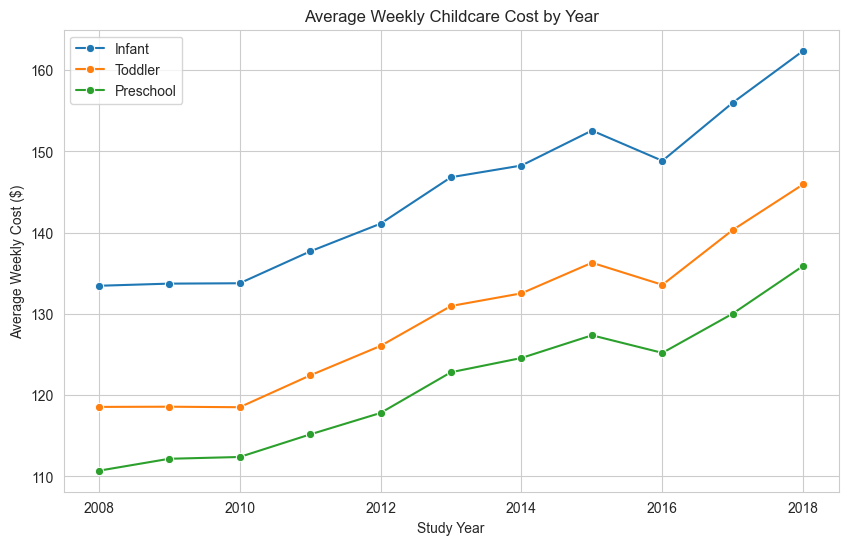

In [54]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=weekly_trend,
    x="StudyYear",
    y="Avg_Weekly_Infant_Cost",
    marker="o",
    label="Infant"
)

sns.lineplot(
    data=weekly_trend,
    x="StudyYear",
    y="Avg_Weekly_Toddler_Cost",
    marker="o",
    label="Toddler"
)

sns.lineplot(
    data=weekly_trend,
    x="StudyYear",
    y="Avg_Weekly_Preschool_Cost",
    marker="o",
    label="Preschool"
)

plt.title("Average Weekly Childcare Cost by Year")
plt.xlabel("Study Year")
plt.ylabel("Average Weekly Cost ($)")
plt.show()

In [55]:
# Preview monthly cost columns
df["Monthly_Infant_Cost"] = df["MCInfant"] * 52 / 12
df["Monthly_Toddler_Cost"] = df["MCToddler"] * 52 / 12
df["Monthly_Preschool_Cost"] = df["MCPreschool"] * 52 / 12
monthly_trend = (
    df.groupby("StudyYear")
    .agg(
        Avg_Monthly_Infant_Cost=("Monthly_Infant_Cost", "mean"),
        Avg_Monthly_Toddler_Cost=("Monthly_Toddler_Cost", "mean"),
        Avg_Monthly_Preschool_Cost=("Monthly_Preschool_Cost", "mean")
    )
    .reset_index()
)

print(monthly_trend)


    StudyYear  Avg_Monthly_Infant_Cost  Avg_Monthly_Toddler_Cost  \
0        2008               578.361997                513.761491   
1        2009               579.503026                513.868368   
2        2010               579.696858                513.599290   
3        2011               596.688035                530.557562   
4        2012               611.481838                546.292970   
5        2013               636.248917                567.585307   
6        2014               642.483280                574.333415   
7        2015               661.133938                590.638212   
8        2016               644.993449                578.870868   
9        2017               676.025456                608.156881   
10       2018               703.698997                632.485713   

    Avg_Monthly_Preschool_Cost  
0                   479.734995  
1                   486.104512  
2                   487.057721  
3                   499.095539  
4                 

In [56]:
# Annual Trend

# CREATE ANNUAL COST COLUMNS
# -----------------------------
df["Annual_Infant_Cost"] = df["MCInfant"] * 52
df["Annual_Toddler_Cost"] = df["MCToddler"] * 52
df["Annual_Preschool_Cost"] = df["MCPreschool"] * 52

annual_trend = (
    df.groupby("StudyYear")
    .agg(
        Avg_Annual_Infant_Cost=("Annual_Infant_Cost", "mean"),
        Avg_Annual_Toddler_Cost=("Annual_Toddler_Cost", "mean"),
        Avg_Annual_Preschool_Cost=("Annual_Preschool_Cost", "mean")
    )
    .reset_index()
)

print(annual_trend)


    StudyYear  Avg_Annual_Infant_Cost  Avg_Annual_Toddler_Cost  \
0        2008             6940.343961              6165.137893   
1        2009             6954.036318              6166.420410   
2        2010             6956.362290              6163.191482   
3        2011             7160.256426              6366.690743   
4        2012             7337.782056              6555.515636   
5        2013             7634.987001              6811.023684   
6        2014             7709.799363              6892.000981   
7        2015             7933.607256              7087.658549   
8        2016             7739.921393              6946.450420   
9        2017             8112.305468              7297.882578   
10       2018             8444.387966              7589.828559   

    Avg_Annual_Preschool_Cost  
0                 5756.819944  
1                 5833.254140  
2                 5844.692657  
3                 5989.146466  
4                 6126.583264  
5              

In [57]:
# Annual cost difference
df["Annual_Cost_Difference"] = (
    df["Annual_Infant_Cost"] - df["Annual_Toddler_Cost"]
)

# Top 10 county-year records with largest annual infant vs toddler gap
top_annual_diff = df[
    [
        "StudyYear",
        "State_Name",
        "County_Name",
        "Annual_Infant_Cost",
        "Annual_Toddler_Cost",
        "Annual_Cost_Difference"
    ]
].sort_values(
    by="Annual_Cost_Difference",
    ascending=False
).head(10)

print(top_annual_diff)

       StudyYear  State_Name            County_Name  Annual_Infant_Cost  \
2066        2018  California          Alpine County            16026.40   
31348       2018    Virginia        Fauquier County            15600.00   
31347       2017    Virginia        Fauquier County            15080.00   
32352       2015    Virginia        Petersburg city            11960.00   
31346       2016    Virginia        Fauquier County            14560.00   
2065        2017  California          Alpine County            14305.72   
2440        2018  California  San Bernardino County            15151.24   
13264       2018    Maryland          Howard County            19740.24   
13286       2018    Maryland      Montgomery County            19740.24   
2198        2018  California            Inyo County            15253.16   

       Annual_Toddler_Cost  Annual_Cost_Difference  
2066               8385.52                 7640.88  
31348              8320.00                 7280.00  
31347          

In [58]:
top_counties_avg_gap = (
    df.groupby(["State_Name", "County_Name"])
    .agg(
        Avg_Annual_Cost_Difference=("Annual_Cost_Difference", "mean")
    )
    .reset_index()
    .sort_values(by="Avg_Annual_Cost_Difference", ascending=False)
    .head(10)
)

print(top_counties_avg_gap)

      State_Name           County_Name  Avg_Annual_Cost_Difference
188   California         Alpine County                 5259.658182
1207    Maryland         Howard County                 5137.080000
1209    Maryland     Montgomery County                 5137.080000
227   California      San Mateo County                 4848.290909
230   California     Santa Cruz County                 4747.836364
229   California    Santa Clara County                 4723.443636
224   California  San Francisco County                 4710.869091
1871    New York       Richmond County                 4697.160000
207   California          Marin County                 4684.301818
1831    New York          Bronx County                 4635.280000


In [59]:
top_counties_with_volatility = (
    df.groupby(["State_Name", "County_Name"])
    .agg(
        Avg_Annual_Cost_Difference=("Annual_Cost_Difference", "mean"),
        Std_Annual_Cost_Difference=("Annual_Cost_Difference", "std")
    )
    .reset_index()
    .sort_values(by="Avg_Annual_Cost_Difference", ascending=False)
    .head(10)
)

print(top_counties_with_volatility)

      State_Name           County_Name  Avg_Annual_Cost_Difference  \
188   California         Alpine County                 5259.658182   
1207    Maryland         Howard County                 5137.080000   
1209    Maryland     Montgomery County                 5137.080000   
227   California      San Mateo County                 4848.290909   
230   California     Santa Cruz County                 4747.836364   
229   California    Santa Clara County                 4723.443636   
224   California  San Francisco County                 4710.869091   
1871    New York       Richmond County                 4697.160000   
207   California          Marin County                 4684.301818   
1831    New York          Bronx County                 4635.280000   

      Std_Annual_Cost_Difference  
188                   941.725688  
1207                  613.606169  
1209                  613.606169  
227                   368.519951  
230                   445.811644  
229                

In [60]:
county_obs = (
    df.groupby(["State_Name", "County_Name"])
    .size()
    .reset_index(name="Observation_Count")
)

print(
    county_obs[
        county_obs["County_Name"].isin(["Richmond County", "Bronx County"])
    ]
)

          State_Name      County_Name  Observation_Count
508          Georgia  Richmond County                 11
1831        New York     Bronx County                 11
1871        New York  Richmond County                 11
1967  North Carolina  Richmond County                 11
2926        Virginia  Richmond County                 11


In [61]:
print(
    df[
        (df["State_Name"] == "New York") &
        (df["County_Name"] == "Richmond County")
    ][
        ["StudyYear", "Annual_Cost_Difference"]
    ]
)

print(
    df[
        (df["State_Name"] == "New York") &
        (df["County_Name"] == "Bronx County")
    ][
        ["StudyYear", "Annual_Cost_Difference"]
    ]
)

       StudyYear  Annual_Cost_Difference
20569       2008                     NaN
20570       2009                     NaN
20571       2010                     NaN
20572       2011                     NaN
20573       2012                     NaN
20574       2013                     NaN
20575       2014                     NaN
20576       2015                     NaN
20577       2016                     NaN
20578       2017                     NaN
20579       2018                 4697.16
       StudyYear  Annual_Cost_Difference
20129       2008                     NaN
20130       2009                     NaN
20131       2010                     NaN
20132       2011                     NaN
20133       2012                     NaN
20134       2013                     NaN
20135       2014                     NaN
20136       2015                     NaN
20137       2016                     NaN
20138       2017                     NaN
20139       2018                 4635.28


In [62]:
county_gap_stats = (
    df.groupby(["County_FIPS_Code", "State_Name", "County_Name"])
    .agg(
        Avg_Annual_Cost_Difference=("Annual_Cost_Difference", "mean"),
        Std_Annual_Cost_Difference=("Annual_Cost_Difference", "std"),
        Valid_Observation_Count=("Annual_Cost_Difference", "count")
    )
    .reset_index()
)

filtered_top = (
    county_gap_stats[
        county_gap_stats["Valid_Observation_Count"] >= 5
    ]
    .sort_values(by="Avg_Annual_Cost_Difference", ascending=False)
    .head(10)
)

print(filtered_top)

      County_FIPS_Code  State_Name           County_Name  \
188               6003  California         Alpine County   
1208             24031    Maryland     Montgomery County   
1206             24027    Maryland         Howard County   
227               6081  California      San Mateo County   
230               6087  California     Santa Cruz County   
229               6085  California    Santa Clara County   
224               6075  California  San Francisco County   
207               6041  California          Marin County   
1203             24021    Maryland      Frederick County   
1205             24025    Maryland        Harford County   

      Avg_Annual_Cost_Difference  Std_Annual_Cost_Difference  \
188                  5259.658182                  941.725688   
1208                 5137.080000                  613.606169   
1206                 5137.080000                  613.606169   
227                  4848.290909                  368.519951   
230                

In [63]:
county_gap_stats["Consistency_Score"] = (
    county_gap_stats["Avg_Annual_Cost_Difference"] /
    county_gap_stats["Std_Annual_Cost_Difference"]
)

In [64]:
# Merge county-level consistency metrics onto each county-year row
df = df.merge(
    county_gap_stats[
        [
            "County_FIPS_Code",
            "Avg_Annual_Cost_Difference",
            "Std_Annual_Cost_Difference",
            "Valid_Observation_Count",
            "Consistency_Score",
        ]
    ],
    on="County_FIPS_Code",
    how="left"
)

"Avg_Annual_Cost_Difference",
"Std_Annual_Cost_Difference",
"Valid_Observation_Count",
"Consistency_Score",



('Consistency_Score',)

In [65]:
final_cols = [
    "StudyYear",
    "State_Name",
    "State_Abbreviation",
    "County_Name",
    "County_FIPS_Code",

    # Weekly costs
    "MCInfant",
    "MCToddler",
    "MCPreschool",

    # Monthly costs
    "Monthly_Infant_Cost",
    "Monthly_Toddler_Cost",
    "Monthly_Preschool_Cost",

    # Annual costs
    "Annual_Infant_Cost",
    "Annual_Toddler_Cost",
    "Annual_Preschool_Cost",

    # Difference metrics
    "Annual_Cost_Difference",

    # Affordability
    "MHI",
    "Infant_Cost_Pct_Income",

    # County-level gap metrics
    "Avg_Annual_Cost_Difference",
    "Std_Annual_Cost_Difference",
    "Valid_Observation_Count",
    "Consistency_Score"
]
df["Infant_Cost_Pct_Income"] = (
    df["Annual_Infant_Cost"] / df["MHI"]
) * 100

df_clean = df[final_cols].copy()

numeric_cols = df_clean.select_dtypes(include="number").columns
df_clean[numeric_cols] = df_clean[numeric_cols].round(2)

df_clean.to_csv("childcare_cleaned_for_pbi_trend.csv", index=False)

print("Export complete: childcare_cleaned_for_pbi_trend.csv")

Export complete: childcare_cleaned_for_pbi_trend.csv


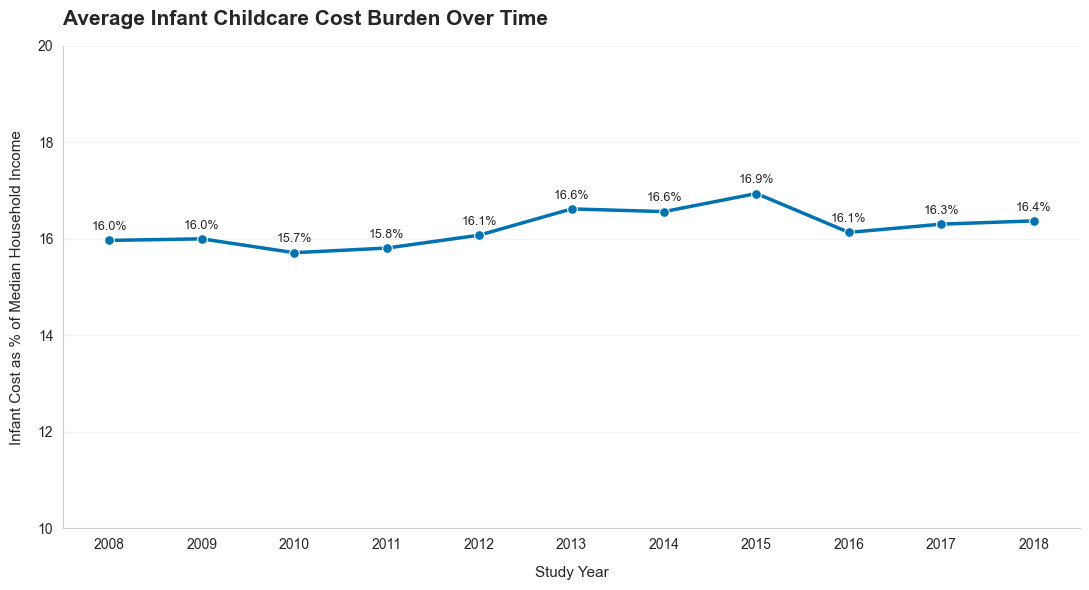

In [66]:
# -----------------------------
# YEARLY TREND: INFANT COST % OF INCOME
# -----------------------------

affordability_trend = (
    df.groupby("StudyYear")
    .agg(
        Avg_Annual_Infant_Cost=("Annual_Infant_Cost", "mean"),
        Avg_MHI=("MHI", "mean")
    )
    .reset_index()
)

affordability_trend["Avg_Infant_Cost_Pct_Income"] = (
    affordability_trend["Avg_Annual_Infant_Cost"] /
    affordability_trend["Avg_MHI"]
) * 100


# -----------------------------
# ACCESSIBLE LINE CHART WITH DATA LABELS
# -----------------------------

plt.figure(figsize=(11, 6))

ax = sns.lineplot(
    data=affordability_trend,
    x="StudyYear",
    y="Avg_Infant_Cost_Pct_Income",
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#0072B2"
)

# Add percentage labels above each point
for x, y in zip(
    affordability_trend["StudyYear"],
    affordability_trend["Avg_Infant_Cost_Pct_Income"]
):
    plt.text(
        x,
        y + 0.15,
        f"{y:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(
    "Average Infant Childcare Cost Burden Over Time",
    fontsize=15,
    weight="bold",
    loc="left",
    pad=15
)

plt.xlabel("Study Year", fontsize=11, labelpad=10)
plt.ylabel("Infant Cost as % of Median Household Income", fontsize=11, labelpad=10)

plt.xticks(
    ticks=affordability_trend["StudyYear"],
    labels=affordability_trend["StudyYear"]
)

plt.ylim(10, 20)

plt.grid(axis="y", alpha=0.25)
plt.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()

plt.show()

In [67]:
map_year = 2018

coverage_pct = (
    df[
        (df["StudyYear"] == map_year) &
        (df["Infant_Cost_Pct_Income"].notna())
    ]["County_FIPS_Code"].count()
    /
    df[df["StudyYear"] == map_year]["County_FIPS_Code"].count()
) * 100

print(f"Coverage for {map_year}: {coverage_pct:.1f}%")

Coverage for 2018: 75.1%


In [68]:
# -----------------------------
# SETTINGS
# -----------------------------
map_year = 2018

geojson_url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"

# Load county GeoJSON
with urllib.request.urlopen(geojson_url) as response:
    counties_geojson = json.load(response)

# Create list of ALL U.S. county FIPS codes from GeoJSON
all_counties = pd.DataFrame({
    "County_FIPS_Code": [
        feature["id"] for feature in counties_geojson["features"]
    ]
})

# PREPARE  THE DATA

df_map = df[df["StudyYear"] == map_year].copy()

df_map["County_FIPS_Code"] = (
    df_map["County_FIPS_Code"]
    .astype(str)
    .str.zfill(5)
)

# Keep only needed columns
df_map = df_map[
    [
        "County_FIPS_Code",
        "County_Name",
        "State_Name",
        "Infant_Cost_Pct_Income"
    ]
]

# Merge  data onto ALL counties
df_full_map = all_counties.merge(
    df_map,
    on="County_FIPS_Code",
    how="left"
)


# CREATE AFFORDABILITY BANDS

band_order = ["<10%", "10–15%", "15–20%", "20–25%", "25%+", "Missing"]

df_full_map["Affordability_Band"] = pd.cut(
    df_full_map["Infant_Cost_Pct_Income"],
    bins=[0, 10, 15, 20, 25, 100],
    labels=["<10%", "10–15%", "15–20%", "20–25%", "25%+"],
    include_lowest=True
)

df_full_map["Affordability_Band"] = (
    df_full_map["Affordability_Band"]
    .astype("object")
    .fillna("Missing")
)

# COMPLETE COUNTY MAP

fig = px.choropleth(
    df_full_map,
    geojson=counties_geojson,
    locations="County_FIPS_Code",
    color="Affordability_Band",
    category_orders={"Affordability_Band": band_order},
    color_discrete_map={
        "<10%": "#deebf7",
        "10–15%": "#9ecae1",
        "15–20%": "#6baed6",
        "20–25%": "#3182bd",
        "25%+": "#08519c",
        "Missing": "#d9d9d9"
    },
    scope="usa",
    hover_data={
        "County_Name": True,
        "State_Name": True,
        "Infant_Cost_Pct_Income": ":.1f"
    },
    title=f"County-Level Infant Childcare Cost Burden ({map_year})"
)

fig.update_geos(visible=False)

fig.update_layout(
    title_x=0.01,
    legend_title_text="Infant Cost as % of Income",
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.write_html("county_infant_cost_map.html", include_plotlyjs="cdn")

![County-Level Infant Childcare Cost Burden (2018)](county_infant_cost_map.png)

*Static preview of the interactive county map. Running the cell above regenerates the interactive version as `county_infant_cost_map.html`; the PNG is a screenshot of that file for display on GitHub, because the embedded interactive map made the notebook too large (over 60 MB) to host.*

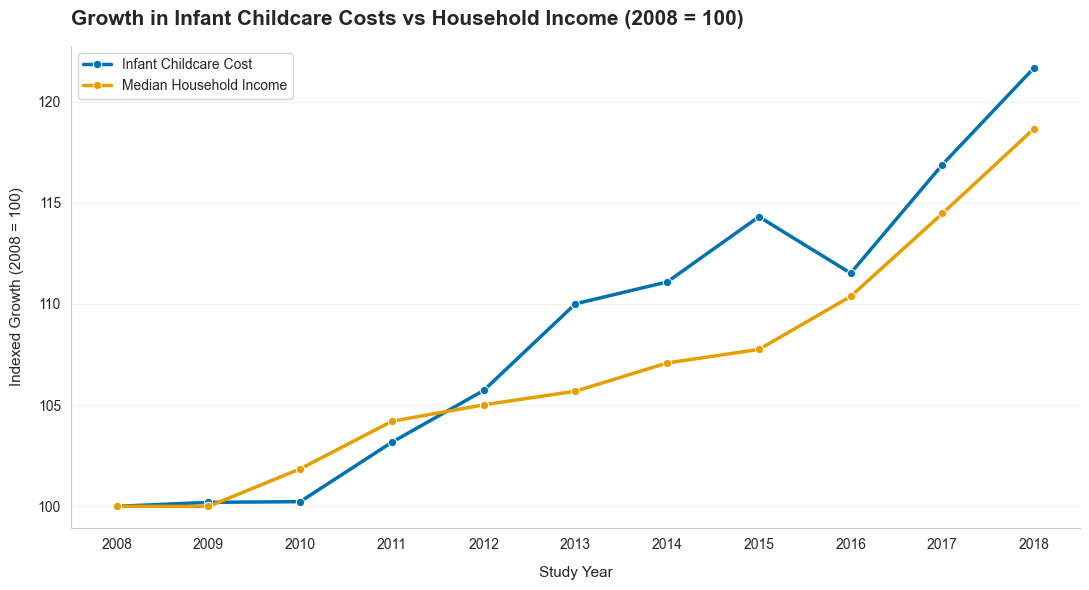

In [69]:
# PREPARE INDEXED TREND DATA

indexed_trend = (
    df.groupby("StudyYear")
    .agg(
        Avg_Annual_Infant_Cost=("Annual_Infant_Cost", "mean"),
        Avg_MHI=("MHI", "mean")
    )
    .reset_index()
)

# Index both series to base year = 2008
base_cost = indexed_trend.loc[
    indexed_trend["StudyYear"] == 2008,
    "Avg_Annual_Infant_Cost"
].iloc[0]

base_income = indexed_trend.loc[
    indexed_trend["StudyYear"] == 2008,
    "Avg_MHI"
].iloc[0]

indexed_trend["Infant_Cost_Index"] = (
    indexed_trend["Avg_Annual_Infant_Cost"] / base_cost
) * 100

indexed_trend["Income_Index"] = (
    indexed_trend["Avg_MHI"] / base_income
) * 100

# -----------------------------
# ACCESSIBLE MULTI-LINE CHART
# -----------------------------
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=indexed_trend,
    x="StudyYear",
    y="Infant_Cost_Index",
    marker="o",
    linewidth=2.5,
    color="#0072B2",
    label="Infant Childcare Cost"
)

sns.lineplot(
    data=indexed_trend,
    x="StudyYear",
    y="Income_Index",
    marker="o",
    linewidth=2.5,
    color="#E69F00",
    label="Median Household Income"
)

plt.title(
    "Growth in Infant Childcare Costs vs Household Income (2008 = 100)",
    fontsize=15,
    weight="bold",
    loc="left",
    pad=15
)

plt.xlabel("Study Year", fontsize=11, labelpad=10)
plt.ylabel("Indexed Growth (2008 = 100)", fontsize=11, labelpad=10)

plt.xticks(indexed_trend["StudyYear"])

plt.grid(axis="y", alpha=0.25)
plt.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()

plt.show()

    StudyYear  Total_Counties  Counties_Above_Threshold  \
0        2008            1424                       790   
1        2009            1901                      1035   
2        2010            1991                      1091   
3        2011            1992                      1120   
4        2012            2053                      1200   
5        2013            2074                      1288   
6        2014            2323                      1402   
7        2015            2398                      1544   
8        2016            2641                      1571   
9        2017            2436                      1484   
10       2018            2360                      1462   

    Pct_Counties_Above_Threshold  
0                      55.477528  
1                      54.445029  
2                      54.796585  
3                      56.224900  
4                      58.451047  
5                      62.102218  
6                      60.352992  
7          

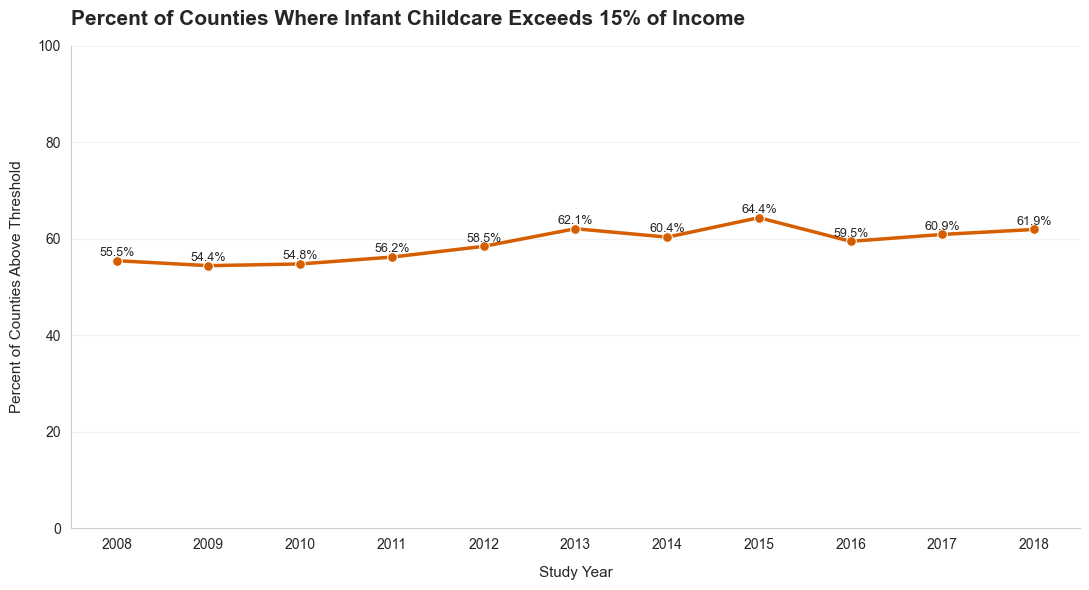

In [70]:
# -----------------------------
# SET AFFORDABILITY THRESHOLD
# -----------------------------
threshold = 15

# -----------------------------
# CALCULATE % OF COUNTIES ABOVE THRESHOLD BY YEAR
# -----------------------------
threshold_trend = (
    df[df["Infant_Cost_Pct_Income"].notna()]
    .groupby("StudyYear")
    .agg(
        Total_Counties=("County_FIPS_Code", "count"),
        Counties_Above_Threshold=(
            "Infant_Cost_Pct_Income",
            lambda x: (x > threshold).sum()
        )
    )
    .reset_index()
)

threshold_trend["Pct_Counties_Above_Threshold"] = (
    threshold_trend["Counties_Above_Threshold"] /
    threshold_trend["Total_Counties"]
) * 100

print(threshold_trend)

# -----------------------------
# ACCESSIBLE LINE CHART
# -----------------------------
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=threshold_trend,
    x="StudyYear",
    y="Pct_Counties_Above_Threshold",
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#D55E00"   # color-blind friendly orange/red
)

# Add labels
for x, y in zip(
    threshold_trend["StudyYear"],
    threshold_trend["Pct_Counties_Above_Threshold"]
):
    plt.text(
        x,
        y + 1,
        f"{y:.1f}%",
        ha="center",
        fontsize=9
    )

plt.title(
    f"Percent of Counties Where Infant Childcare Exceeds {threshold}% of Income",
    fontsize=15,
    weight="bold",
    loc="left",
    pad=15
)

plt.xlabel("Study Year", fontsize=11, labelpad=10)
plt.ylabel("Percent of Counties Above Threshold", fontsize=11, labelpad=10)

plt.xticks(threshold_trend["StudyYear"])

plt.ylim(0, 100)

plt.grid(axis="y", alpha=0.25)
plt.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()

plt.show()

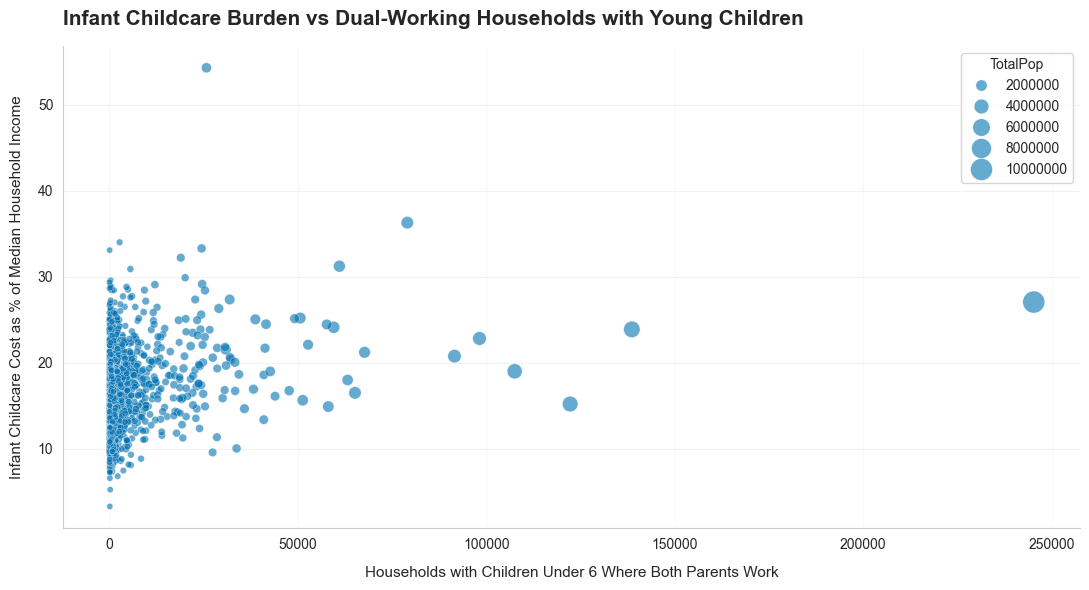

In [71]:
# -----------------------------
# FILTER TO VALID RECORDS
# -----------------------------
df_workforce = df[
    df["Infant_Cost_Pct_Income"].notna() &
    df["H_Under6_BothWork"].notna() &
    df["TotalPop"].notna()
].copy()

# Optional: focus on latest year for cleaner story
df_workforce = df_workforce[df_workforce["StudyYear"] == 2018]

# -----------------------------
# SCATTERPLOT
# -----------------------------
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_workforce,
    x="H_Under6_BothWork",
    y="Infant_Cost_Pct_Income",
    size="TotalPop",
    sizes=(20, 250),
    alpha=0.6,
    color="#0072B2"
)

plt.title(
    "Infant Childcare Burden vs Dual-Working Households with Young Children",
    fontsize=15,
    weight="bold",
    loc="left",
    pad=15
)

plt.xlabel(
    "Households with Children Under 6 Where Both Parents Work",
    fontsize=11,
    labelpad=10
)

plt.ylabel(
    "Infant Childcare Cost as % of Median Household Income",
    fontsize=11,
    labelpad=10
)

plt.grid(axis="y", alpha=0.25)
plt.grid(axis="x", alpha=0.10)

sns.despine()
plt.tight_layout()

plt.show()